# Week 3 & 4 Exercises

- DSC540-T301
- Saebastion Cole

## The Data Wrangling Workshop: Activity 3.01, page 155
### Activity 3.01: Generating Statistics from a CSV file

In [964]:
# Start with the imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
housing_data = pd.read_csv('./data/Boston_housing.csv')

In [965]:
# Show the first 10 rows
housing_data.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311,15.2,386.71,17.10,18.9


In [966]:
# Show the total row count
# I found you can also do this using the shape attribute
len(housing_data)

506

In [967]:
# Create a new dataframe with only specific columns (the excersise asks to remove CHAS, NOX, B, and LSTAT)
clean_housing_data = housing_data[['CRIM', 'ZN', 'INDUS', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'PRICE']]

# Show the last 7 rows (the naming of these functions reminded me of Unix cat and tail command)
clean_housing_data.tail(7)

,CRIM,ZN,INDUS,RM,AGE,DIS,RAD,TAX,PTRATIO,PRICE
499,0.17783,0.0,9.69,5.569,73.5,2.3999,6,391,19.2,17.5
500,0.22438,0.0,9.69,6.027,79.7,2.4982,6,391,19.2,16.8
501,0.06263,0.0,11.93,6.593,69.1,2.4786,1,273,21.0,22.4
502,0.04527,0.0,11.93,6.120,76.7,2.2875,1,273,21.0,20.6
503,0.06076,0.0,11.93,6.976,91.0,2.1675,1,273,21.0,23.9
504,0.10959,0.0,11.93,6.794,89.3,2.3889,1,273,21.0,22.0
505,0.04741,0.0,11.93,6.030,80.8,2.5050,1,273,21.0,11.9


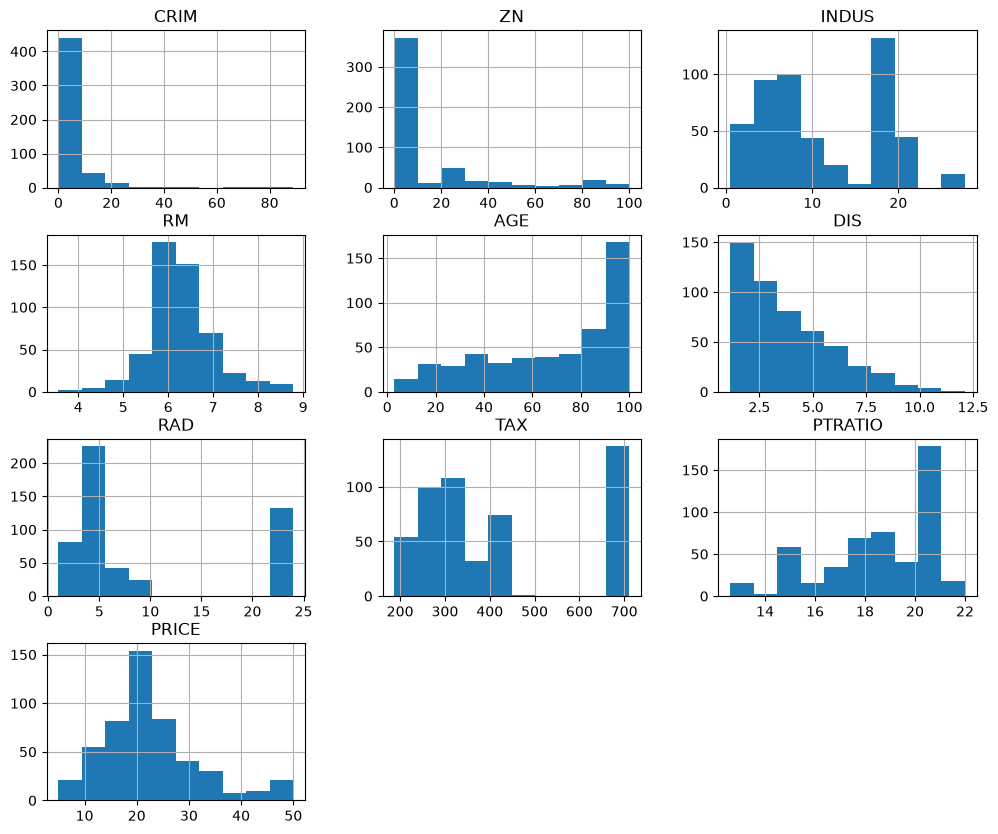

In [968]:
# Plot the histograms of all of the variables
clean_housing_data.hist(figsize=(12, 10))
plt.show()

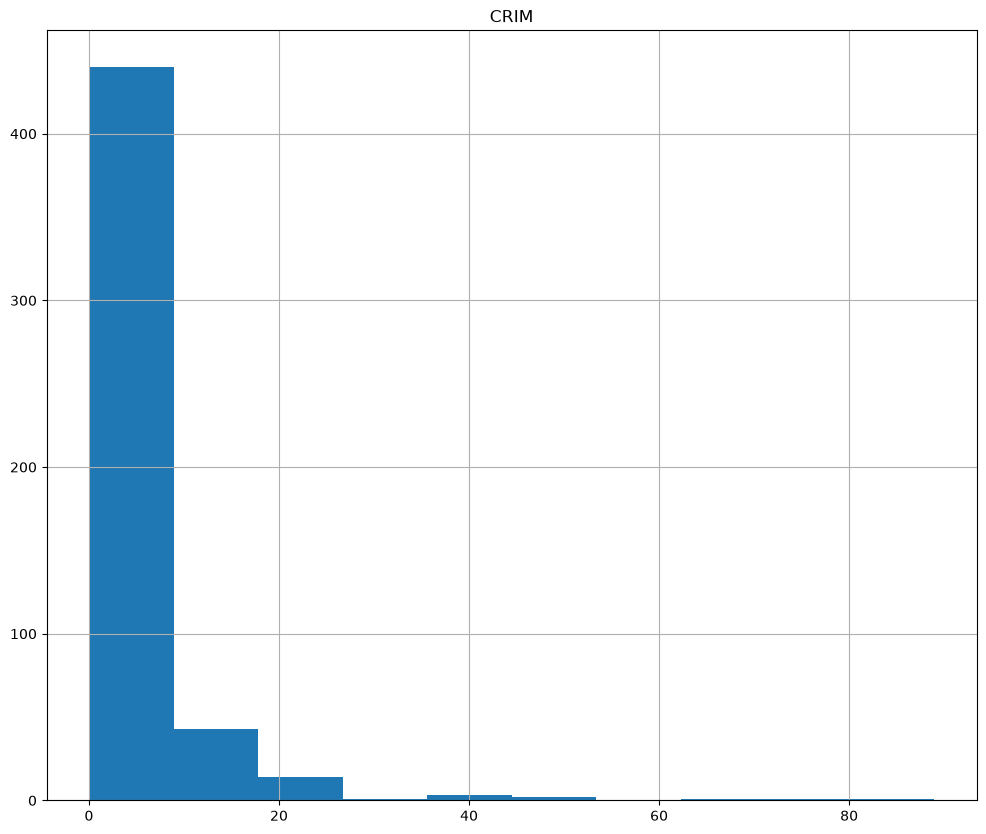

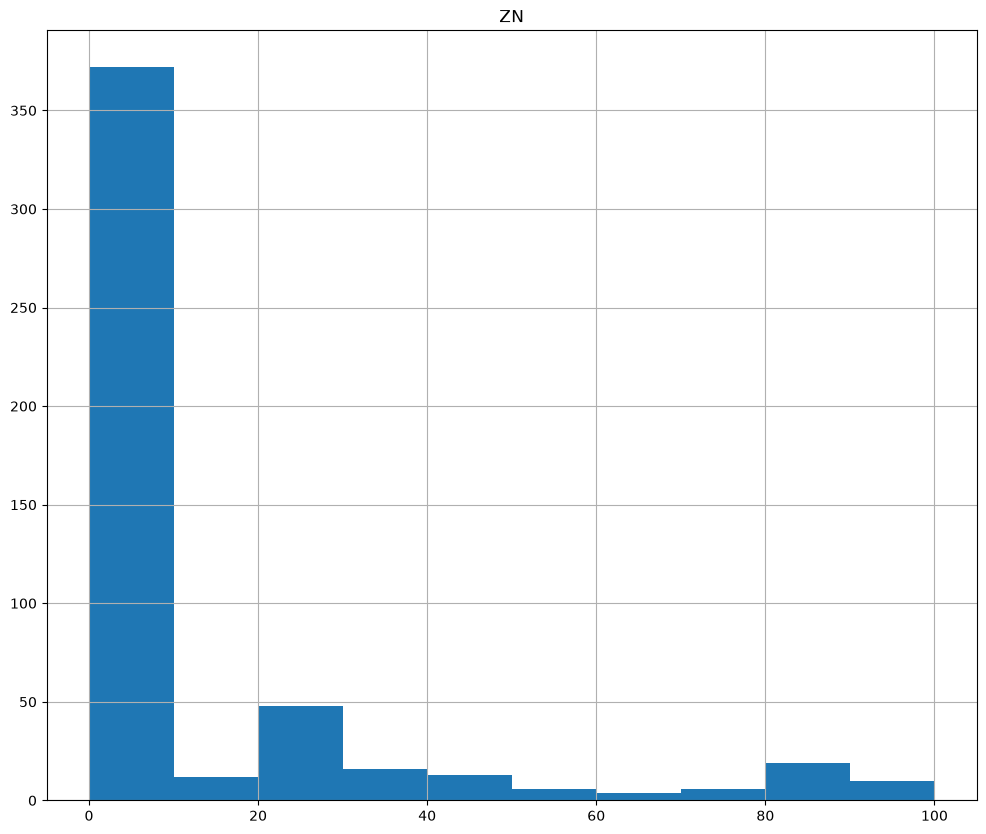

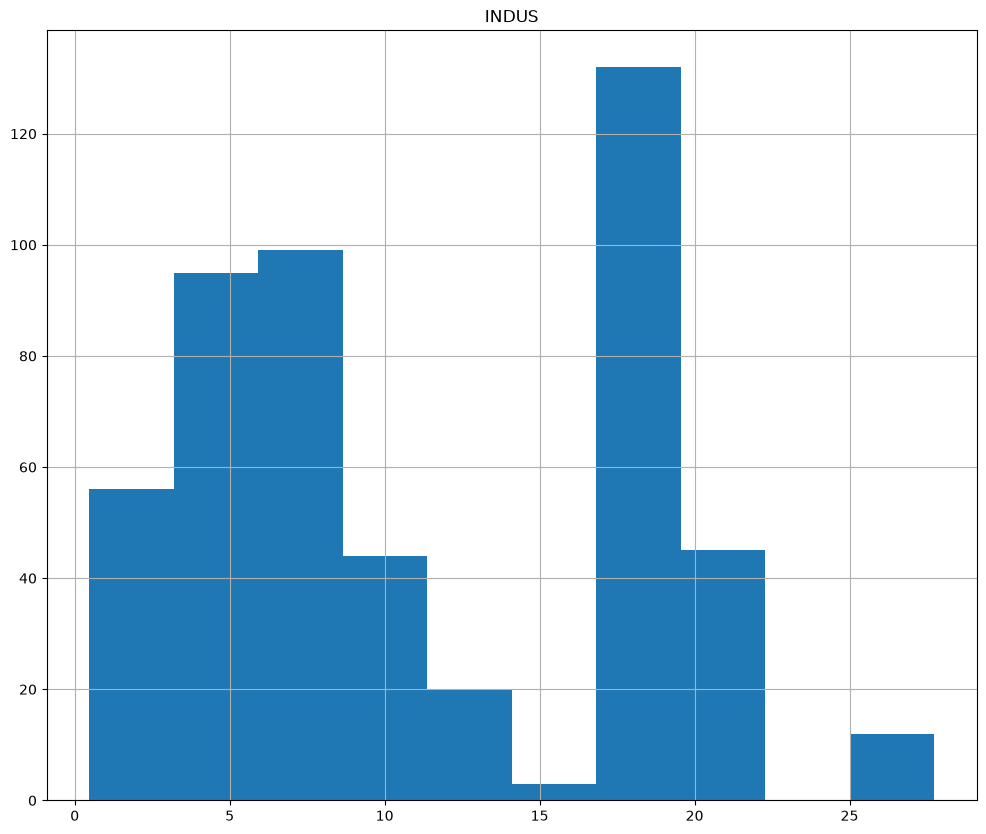

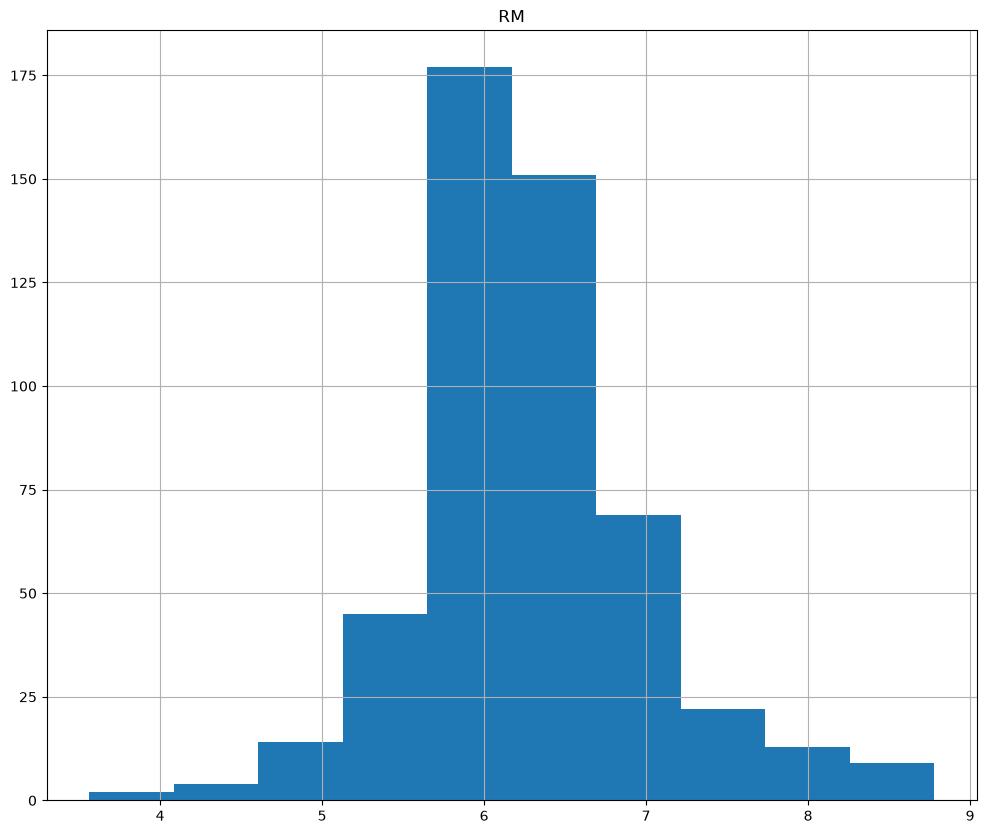

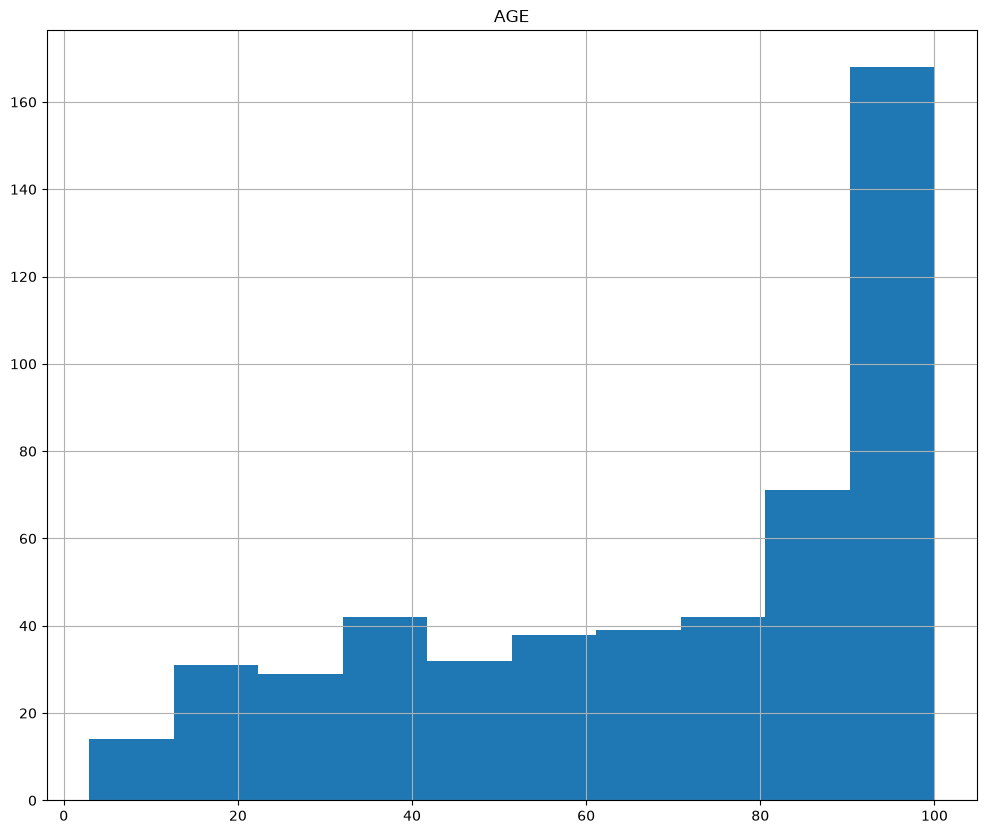

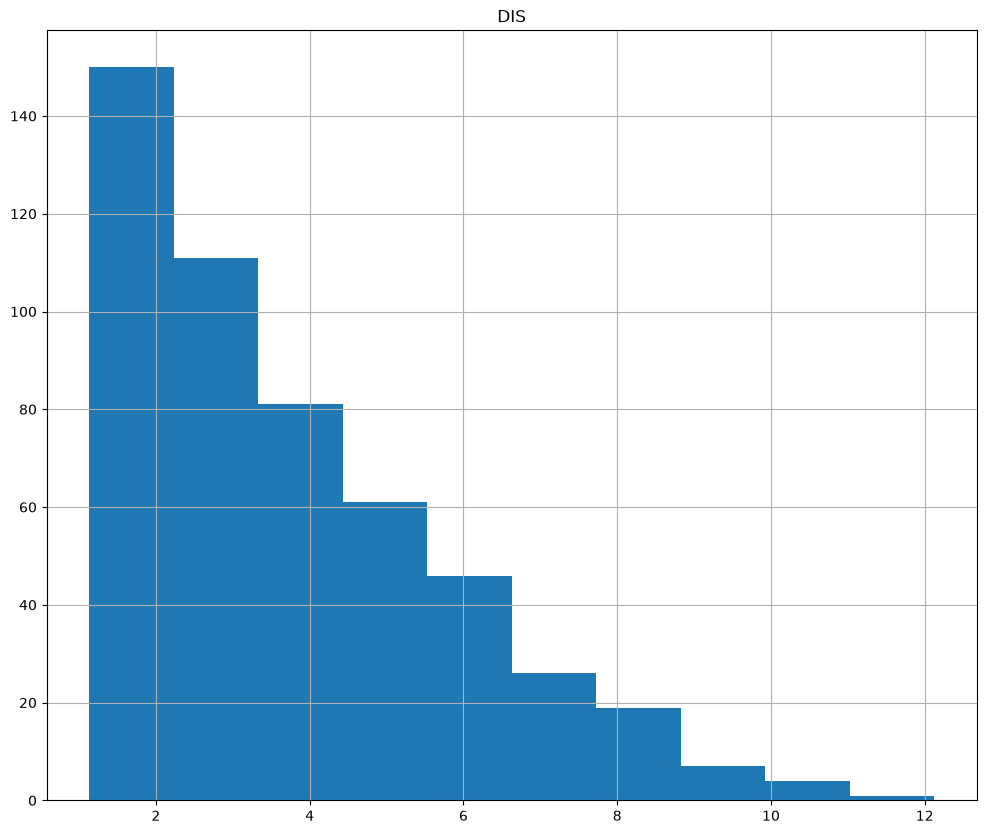

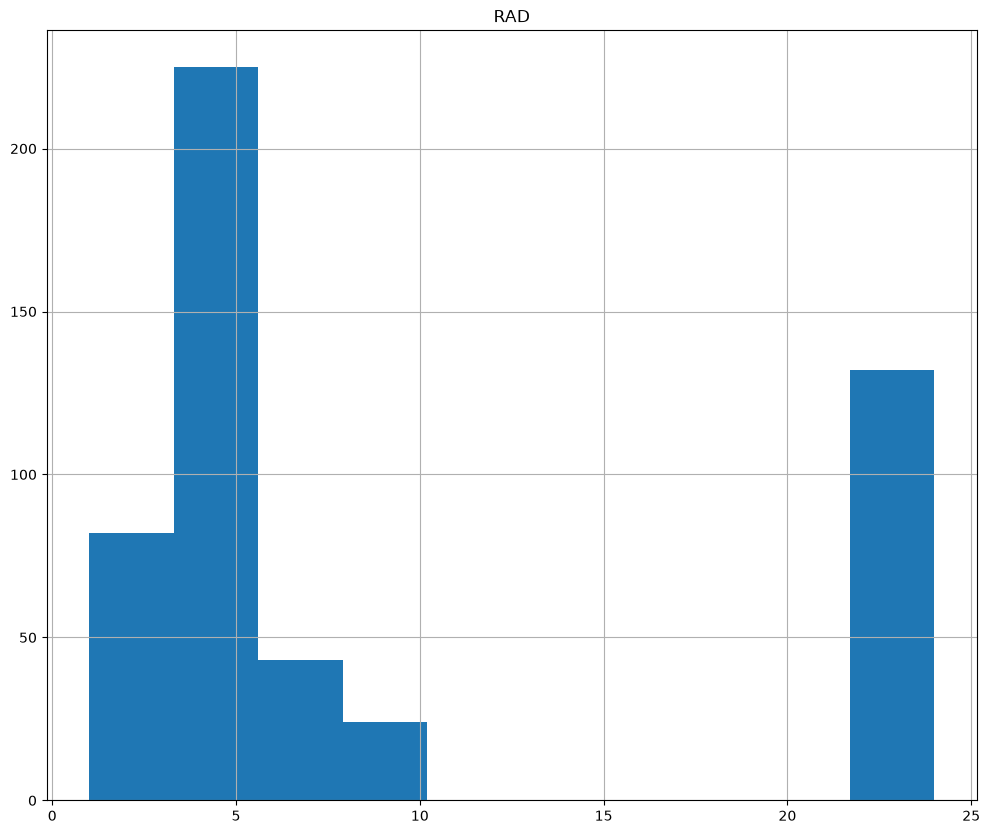

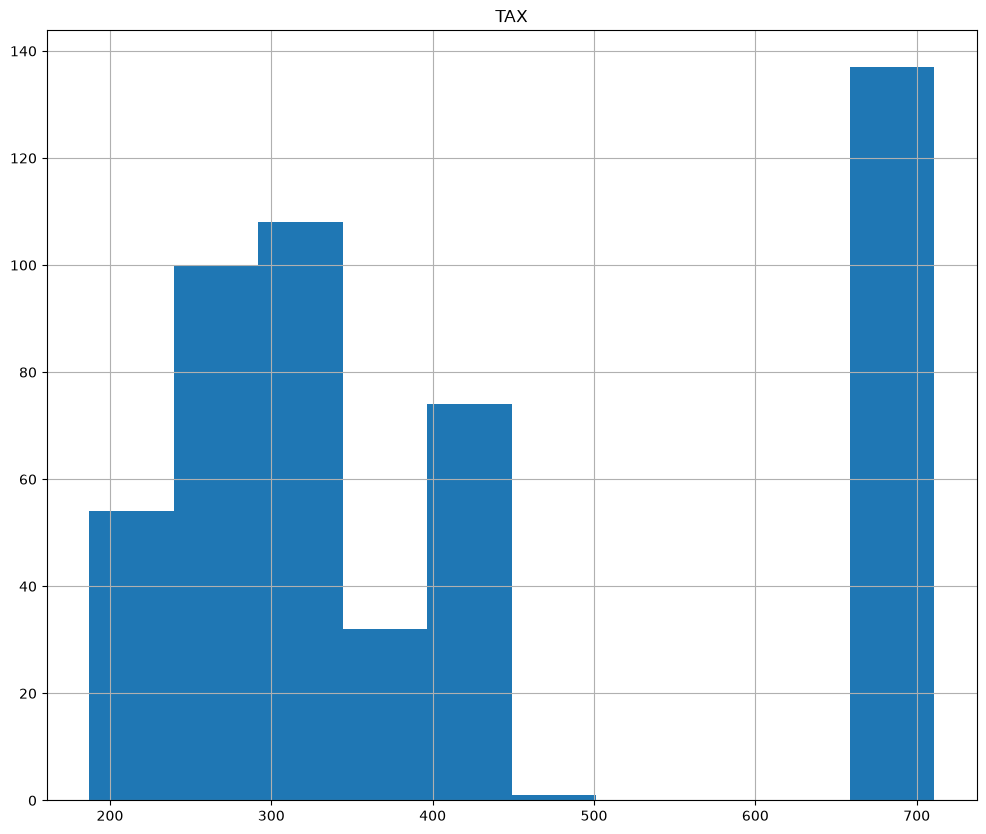

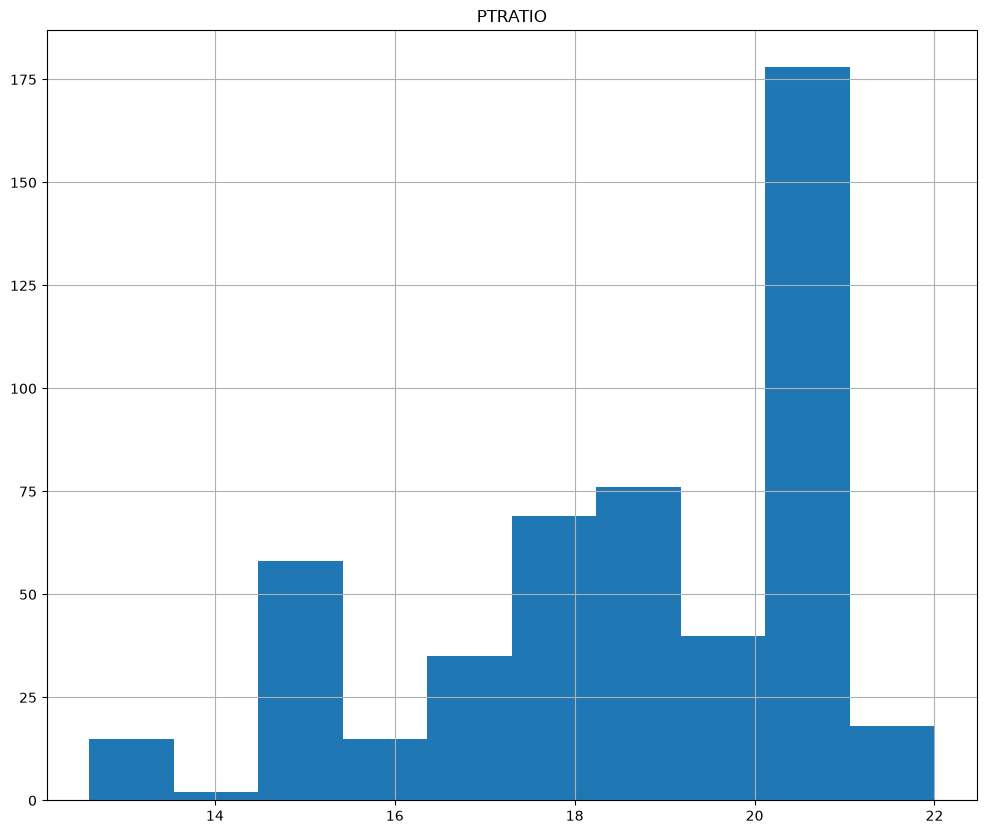

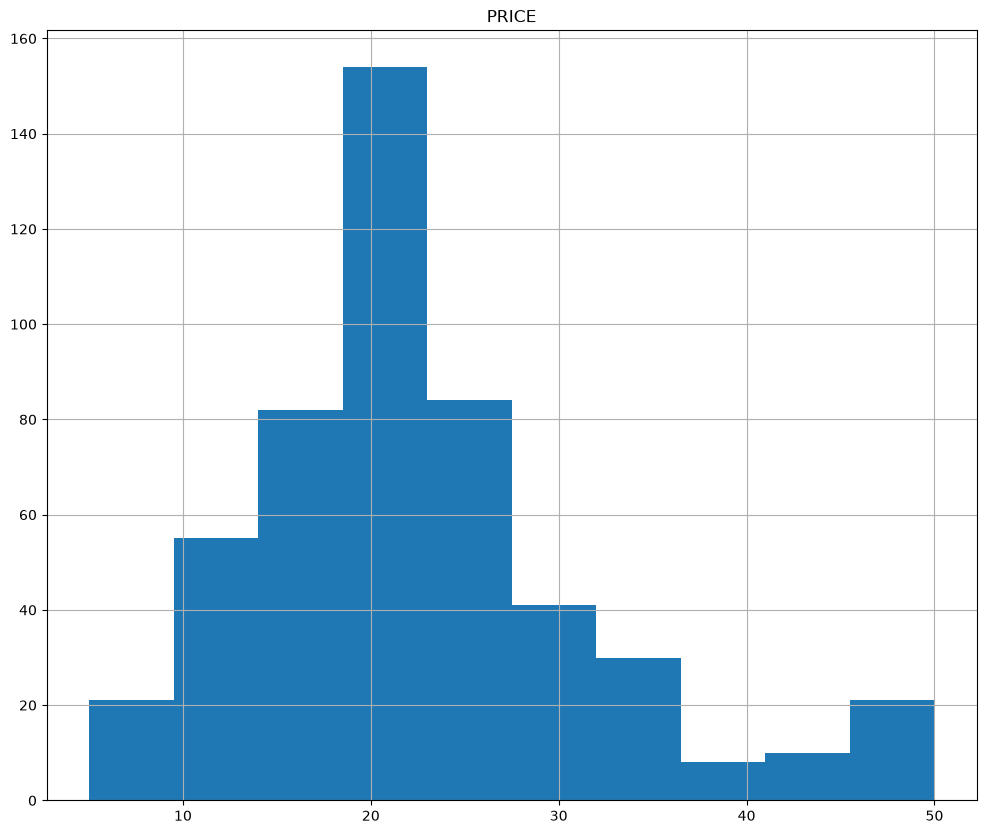

In [969]:
# Now plot each of them using a for lop
for column in clean_housing_data.columns:
    clean_housing_data[column].hist(figsize=(12, 10))
    plt.title(column)
    plt.show()

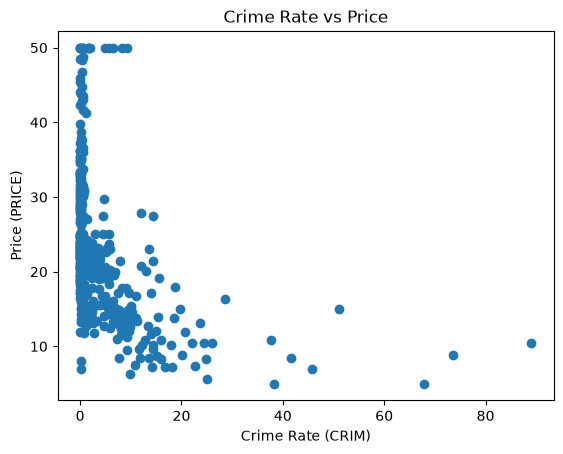

In [970]:
# Create a scatter plot of crime rate vs price
plt.scatter(clean_housing_data['CRIM'], clean_housing_data['PRICE'])
plt.xlabel('Crime Rate (CRIM)')
plt.ylabel('Price (PRICE)')
plt.title('Crime Rate vs Price')
plt.show()

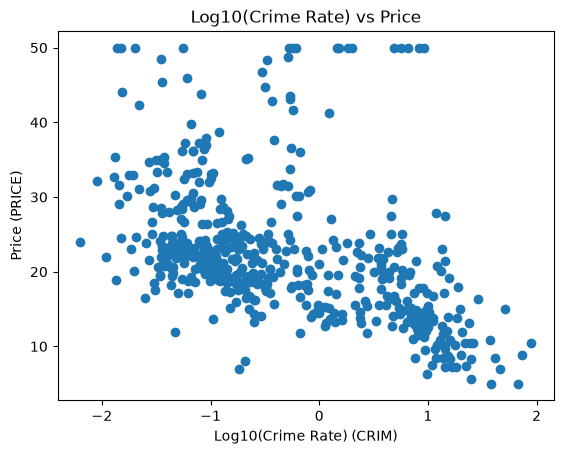

In [971]:
# Plot log10(crime) versus price
plt.scatter(np.log10(clean_housing_data['CRIM']), clean_housing_data['PRICE'])
plt.xlabel('Log10(Crime Rate) (CRIM)')
plt.ylabel('Price (PRICE)')
plt.title('Log10(Crime Rate) vs Price')
plt.show()

In [972]:
# Calculate statistics on the data like average rooms, median home age, distance between employment centers, and median price

# Data frames have all of these calculations built in. I am going to assign them to variables to make a formatted print
average_rooms = clean_housing_data['RM'].mean()
median_home_age = clean_housing_data['AGE'].median()
distance_to_employment = clean_housing_data['DIS'].mean()
median_price = clean_housing_data['PRICE'].median()

# Another ask was to get a calculation of the percentage of low priced homes (This book considered it as ONLY $20,000 I can't imaging a home being that cheap)
total_homes = len(clean_housing_data)
low_priced_homes = len(clean_housing_data[clean_housing_data['PRICE'] < 20])
percentage_low_priced_homes = (low_priced_homes / total_homes) * 100

print("Average Rooms: " + str(average_rooms))
print("Median Home Age: " + str(median_home_age))
print("Distance to Employment Centers: " + str(distance_to_employment))
print("Median Price: " + str(median_price))
print("Percentage of Low Priced Homes: " + str(percentage_low_priced_homes))

Average Rooms: 6.284634387351779
Median Home Age: 77.5
Distance to Employment Centers: 3.795042687747036
Median Price: 21.2
Percentage of Low Priced Homes: 41.50197628458498


## The Data Wrangling Workshop: Activity 4.01, page 233
### Working With The Adult Income DataSet

In [973]:
# Libraries are already loaded by previous exercise all we need to do is load data

# The provided dataset didn't have the headers added there were provided in a seperate file.
headers = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
             'marital-status', 'occupation', 'relationship', 'sex',
             'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

# I have to load the data without headers to assign them after.
adult_income_data = pd.read_csv('./data/adult_income_data.csv', header=None)
adult_income_data.columns = headers

adult_income_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,<=50K


In [974]:
# Part of the requirements is that I load in the data via reading the file itself.
# A little confused by this and looked at the example in the provided github this was left out.
# I am going to leave this commented out because np and pandas are very optimized this is really slow compared.


# First I create the dataframe object
#adult_income_data_text = pd.DataFrame(columns=headers)

# Loop through the file adding a data record line by line
#with open('./data/adult_income_data.csv') as f:
#    for line in f:
#            values = [value.strip() for value in line.strip().split(',')]
#            adult_income_data_text.loc[len(adult_income_data_text)] = values


#adult_income_data_text.head()

In [975]:
# One thing I did notice is that the data is somewhat complete I am going to just leave out values that do not have all required fields
adult_income_data = adult_income_data[(adult_income_data["occupation"] != " ?")]

# This will show me where in the data is missing
adult_income_data.isnull().sum()

# This data set has no missing values

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [976]:
# Create a new dataframe with only age education and occupation
adult_income_data_subset = adult_income_data[['age', 'education', 'occupation']]
adult_income_data_subset.head()

,age,education,occupation
0,39,Bachelors,Adm-clerical
1,50,Bachelors,Exec-managerial
2,38,HS-grad,Handlers-cleaners
3,53,11th,Handlers-cleaners
4,28,Bachelors,Prof-specialty


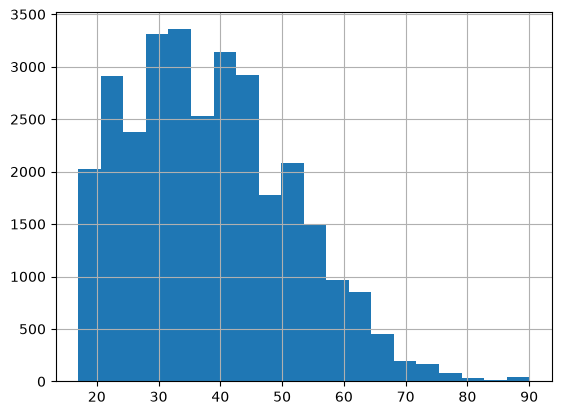

In [977]:
# Plot a histogram of age with a bin size of 20
adult_income_data['age'].hist(bins=20)
plt.show()

In [978]:
# Create a function to strip white space characters
def strip_whitespace(str):
    return str.strip()

In [979]:
# Use apply to use it on the dataframe
for col in adult_income_data.select_dtypes(include=['object']).columns:
    adult_income_data[col] = adult_income_data[col].apply(strip_whitespace)

adult_income_data.head()

C:\Users\saeba\AppData\Local\Temp\ipykernel_5204\3538011868.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in adult_income_data.select_dtypes(include=['object']).columns:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,<=50K


In [980]:
# Get the number of adults between the ages of 30 and 50
age_between_30_and_50 = adult_income_data[(adult_income_data['age'] >= 30) & (adult_income_data['age'] <= 50)]
# Display the length of the subset dataset.
len(age_between_30_and_50)

16015

In [981]:
# Group the records by age and education to find how the mean age is distributed

# NumPy groupby function reorganizes the data.
age_education_group = adult_income_data.groupby(['age', 'education'])

# Now just show the age mean.
age_education_group["age"].mean()

age  education   
17   10th            17.0
     11th            17.0
     12th            17.0
     5th-6th         17.0
     7th-8th         17.0
                     ... 
90   Bachelors       90.0
     HS-grad         90.0
     Masters         90.0
     Prof-school     90.0
     Some-college    90.0
Name: age, Length: 935, dtype: float64

In [982]:
# Group by occupation and show the summary statistics of age. 
occupation_group = adult_income_data.groupby('occupation')

# The describe function will give the summary of stats
occupation_group['age'].describe()

,count,mean,std,min,25%,50%,75%,max
occupation,,,,,,,,
Adm-clerical,3770.0,36.964456,13.362998,17.0,26.0,35.0,46.0,90.0
Armed-Forces,9.0,30.222222,8.089774,23.0,24.0,29.0,34.0,46.0
Craft-repair,4099.0,39.031471,11.606436,17.0,30.0,38.0,47.0,90.0
Exec-managerial,4066.0,42.169208,11.974548,17.0,33.0,41.0,50.0,90.0
Farming-fishing,994.0,41.211268,15.070283,17.0,29.0,39.0,52.0,90.0
Handlers-cleaners,1370.0,32.165693,12.372635,17.0,23.0,29.0,39.0,90.0
Machine-op-inspct,2002.0,37.715285,12.068266,17.0,28.0,36.0,46.0,90.0
Other-service,3295.0,34.949621,14.521508,17.0,22.0,32.0,45.0,90.0
Priv-house-serv,149.0,41.724832,18.633688,17.0,24.0,40.0,57.0,81.0


In [983]:
# Find which profession has the oldest workers on average.

# To do this I will grab the mean age for each occupation then list them in ascending order.
# This gives me Exec-managerial as the occupation with the oldest average age. This would make sense as management role usually requires tenure.
occupation_group['age'].mean().sort_values(ascending=False)

occupation
Exec-managerial      42.169208
Priv-house-serv      41.724832
Farming-fishing      41.211268
Prof-specialty       40.517633
Transport-moving     40.197871
Craft-repair         39.031471
Protective-serv      38.953775
Machine-op-inspct    37.715285
Sales                37.353973
Tech-support         37.022629
Adm-clerical         36.964456
Other-service        34.949621
Handlers-cleaners    32.165693
Armed-Forces         30.222222
Name: age, dtype: float64

In [984]:
# Which profession has its largest share of the workforce above the 75th percentile.

# First, get the 75th percentile of age.
age_75th_percentile = adult_income_data['age'].quantile(0.75)

# Now find the jobs data in the subset.
occupation_above_75th = adult_income_data[adult_income_data['age'] > age_75th_percentile].groupby('occupation').size() / adult_income_data.groupby('occupation').size()

# Display the occupation with the largest share above the 75th percentile.
occupation_above_75th.sort_values(ascending=False)


occupation
Priv-house-serv      0.369128
Farming-fishing      0.323944
Exec-managerial      0.310379
Transport-moving     0.276143
Prof-specialty       0.259662
Sales                0.244932
Craft-repair         0.242010
Protective-serv      0.238829
Machine-op-inspct    0.216284
Adm-clerical         0.214854
Other-service        0.203945
Tech-support         0.182112
Handlers-cleaners    0.131387
Armed-Forces              NaN
dtype: float64

In [985]:
# Use a subset and groupby to find outliers

# To do this instead of just grabbing one range like the last one (> 75%) I am going to grab both ends
q1 = adult_income_data['age'].quantile(0.25)
q3 = adult_income_data['age'].quantile(0.75)
iqr = q3 - q1

# Define outliers as those below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
outliers = adult_income_data[(adult_income_data['age'] < (q1 - 1.5 * iqr)) | (adult_income_data['age'] > (q3 + 1.5 * iqr))]

# Group the outliers by occupation to see which occupations have the most extreme ages
outliers.groupby('occupation').size().sort_values(ascending=False)

occupation
Exec-managerial      33
Prof-specialty       25
Sales                22
Adm-clerical         22
Other-service        20
Farming-fishing      13
Craft-repair         11
Machine-op-inspct     6
Protective-serv       6
Priv-house-serv       6
Handlers-cleaners     4
Transport-moving      4
dtype: int64

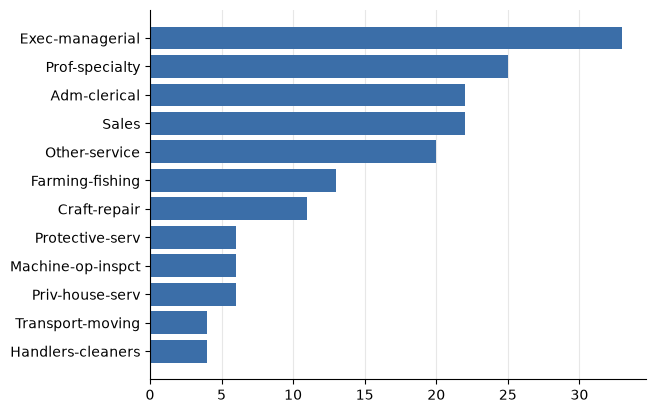

In [986]:
# Plot the outlier values on a bar chart

# Count outliers per occupation; sort ascending so the largest bar ends up at the top
outlier_counts = outliers.groupby('occupation').size().sort_values()

fig, ax = plt.subplots()
ax.barh(outlier_counts.index, outlier_counts.values, color='#3B6EA8')


ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)

# This doesn't quite match the example but that makes sense because it wasn't looking at only outliers.
plt.show()


In [987]:
# Merge the outlier and original data matching by key values to remove outliers from the data

# I am merging based on the index not "common keys". This should be more accurate because reading the documentation 
# I found the indexes dont change after being subsetted.
merged = adult_income_data.reset_index().merge(
    outliers.reset_index()[['index']],
    on='index',
    how='left',
    indicator=True
)

merged.head()

,index,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,sex,capital-gain,capital-loss,hours-per-week,native-country,income,_merge
0,0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,<=50K,left_only
1,1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,<=50K,left_only
2,2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,<=50K,left_only
3,3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,<=50K,left_only
4,4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,<=50K,left_only


## Create a series and practice basic arithmetic steps

In [988]:
#a. Series 1 = 7.3, -2.5, 3.4, 1.5

#          i. Index = ‘a’, ‘c’, ‘d’, ‘e’

s1 = pd.Series([7.3, -2.5, 3.4, 1.5], index=['a', 'c', 'd', 'e'])

s1

a    7.3
c   -2.5
d    3.4
e    1.5
dtype: float64

In [989]:
#b. Series 2 = -2.1, 3.6, -1.5, 4, 3.1

#          i. Index = ‘a’, ‘c’, ‘e’, ‘f’, ‘g’

s2 = pd.Series([-2.1, 3.6, -1.5, 4, 3.1], index=['a', 'c', 'e', 'f', 'g'])

s2

a   -2.1
c    3.6
e   -1.5
f    4.0
g    3.1
dtype: float64

In [990]:
# Add S1 and S2

# Since the indexes don't match perfectly I am including the fill_value=0 to handle missing indexes.
s1.add(s2, fill_value=0)

a    5.2
c    1.1
d    3.4
e    0.0
f    4.0
g    3.1
dtype: float64

In [991]:
# Subtract S1 from S2

# Similarly to the add I am using the subtract function
s2.subtract(s1, fill_value=0)

a   -9.4
c    6.1
d   -3.4
e   -3.0
f    4.0
g    3.1
dtype: float64